# Inference and Validation

## Inputs:
- Trained models from [trained_models](trained_models).
- Gridded points (over grounded ice) from [data/YX_long_tensor.pt](data/YX_long_tensor.pt)
- Alongside [data/combined_mask.pt](data/combined_mask.pt) and [data/stricter_combined_mask.pt](data/stricter_combined_mask.pt) to go back from full grid inference to the valid set of these inference points on a 2D grid. 

## Outputs: 
- Visualisations
- BMB estimates

In [17]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

from models import FluxNet
from models import compute_divergence_field

from configs import N_ensemble
from utils import spatial_subsample

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


# Load

In [18]:
# Inference grid (but flattened) on Bedmap3 grid
XY_long_tensor = torch.load("data/XY_long_tensor.pt")

combined_mask = torch.load("data/combined_mask.pt")
stricter_combined_mask = torch.load("data/stricter_combined_mask.pt")

# Load model 0
# Initialise model architecture and load trained weights
model_0 = FluxNet().to(device)
model_0.load_state_dict(torch.load("trained_models/fluxnet_run_0_trained_model.pth"))
# Set model to evaluation mode (no compgraph)
model_0.eval()

FluxNet(
  (inp): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): SiLU()
  )
  (trunk): ModuleList(
    (0-5): 6 x _ResBlock(
      (lin1): Linear(in_features=256, out_features=256, bias=True)
      (lin2): Linear(in_features=256, out_features=256, bias=True)
      (act): SiLU()
    )
  )
  (head_df_psi): Linear(in_features=256, out_features=1, bias=True)
  (head_cf_phi): Linear(in_features=256, out_features=1, bias=True)
)

# 2. Evaluate on training data

How well did the model learn to represent the data it has been trained on? 

In [19]:
data = torch.load("data/flux_tensor.pt", weights_only = False)

# Subsample to reduce data - this is not random but sptially distributed on purpose
subset = spatial_subsample(data, n_cells = 400)
print(subset.shape)

# Or overwrite with full dataset but takes a while to run inference on the full dataset and to visualise
# subset = data

# Split into x and y to match model input and output
subset_x = subset[:, :2].to(device)
subset_y = subset[:, 2:].to(device)

torch.Size([8305, 4])


In [20]:
# grad must be on for divergence computation, so we set requires_grad = True
flux_prediction = model_0(subset_x.requires_grad_(True))

div_field = compute_divergence_field(
    mean_pred = flux_prediction, 
    x_grad = subset_x)

rmse_field = torch.sqrt(torch.mean((flux_prediction - subset_y) ** 2, dim = 1))
me_field = torch.mean((flux_prediction - subset_y), dim = 1)

me_field.mean().item()

0.007679292466491461

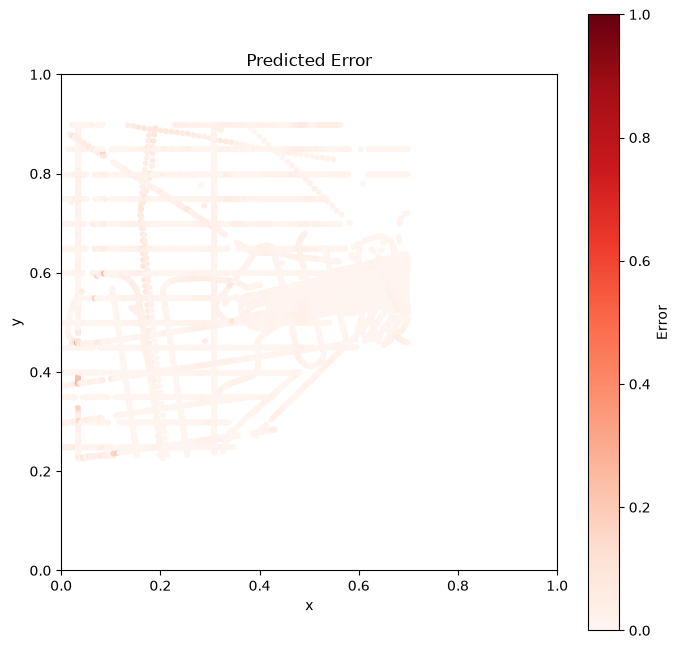

In [21]:
plt.figure(figsize = (8, 8))
plt.scatter(
    subset_x[:, 0].cpu().detach().numpy(), 
    subset_x[:, 1].cpu().detach().numpy(),
    c = me_field.cpu().detach().numpy(), 
    cmap = "Reds", 
    vmin = 0, vmax = 1,
    s = 10)
plt.colorbar(label = "Error")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Predicted Error")
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.gca().set_aspect("equal")
plt.show()

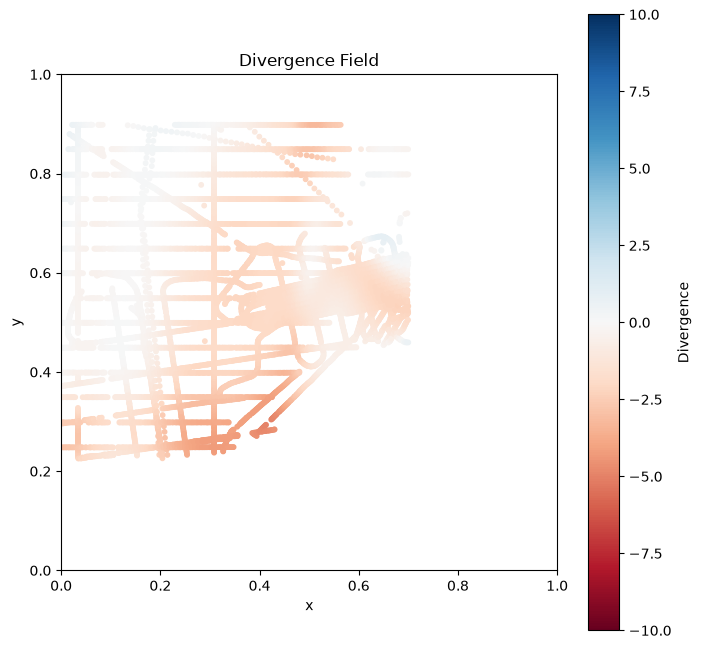

In [22]:
plt.figure(figsize = (8, 8))
plt.scatter(
    subset_x[:, 0].cpu().detach().numpy(), 
    subset_x[:, 1].cpu().detach().numpy(),
    c = div_field.cpu().detach().numpy(), 
    cmap = "RdBu", 
    vmin = -10, vmax = 10,
    s = 10)
plt.colorbar(label = "Divergence")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divergence Field")
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.gca().set_aspect("equal")
plt.show()

## 3. Inference over Bedmap grid

In [23]:
def run_inference_in_batches(model, XY_input_tensor, batch_size = 10000):
    """
    Run inference on a model in batches to avoid memory issues.
    """
    # Move model to device
    model = model.to(device)
    # Put in eval mode
    model.eval()

    # Move data to device (not too big for memory)
    XY_input_tensor = XY_input_tensor.to(device).to(torch.float32)
        
    # Total length
    N = XY_input_tensor.shape[0]

    # container for divergence batches
    div_container = torch.empty((N,), dtype = torch.float32, device = "cpu")
    
    for i in range(0, N, batch_size):

        # Define end index
        j = min(i + batch_size, N)

        print(f"Processing batch {i} to {j}...")

        # Subset batch
        XY_batch = XY_input_tensor[i : j , :]

        # Enable gradients
        XY_batch = XY_batch.requires_grad_(True)

        flux_predictions_batch = model(XY_batch)


        div_batch = compute_divergence_field(
            mean_pred = flux_predictions_batch, 
            x_grad = XY_batch)
        
        # For now only return divergence
        div_container[i:j] = div_batch.detach().cpu() 

        del div_batch
        del flux_predictions_batch
        torch.cuda.empty_cache()

    return div_container

In [24]:
divergences_flat = run_inference_in_batches(model_0, XY_long_tensor, batch_size = 10_000)

print("Divergence shape:", divergences_flat.shape)

Processing batch 0 to 10000...
Processing batch 10000 to 20000...
Processing batch 20000 to 30000...
Processing batch 30000 to 40000...
Processing batch 40000 to 50000...
Processing batch 50000 to 60000...
Processing batch 60000 to 70000...
Processing batch 70000 to 80000...
Processing batch 80000 to 90000...
Processing batch 90000 to 100000...
Processing batch 100000 to 110000...
Processing batch 110000 to 120000...
Processing batch 120000 to 130000...
Processing batch 130000 to 140000...
Processing batch 140000 to 144000...
Divergence shape: torch.Size([144000])


In [25]:
# Select mask
mask = stricter_combined_mask

# 1D -> 2D using shapes from the mask
divergences_2D = divergences_flat.unsqueeze(1).reshape(mask.shape[0], mask.shape[1])
print("Divergence field shape:", divergences_2D.shape)

# Mask out invalid values (where mask != 1) and replace with NaN
divergences_2D_valid = divergences_2D.masked_fill(mask != 1, float("nan"))

Divergence field shape: torch.Size([360, 400])


/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_18624/397588568.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(XY_long_tensor[:, 0].reshape(mask.shape)).cpu().detach().numpy(),
/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_18624/397588568.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(XY_long_tensor[:, 1].reshape(mask.shape)).cpu().detach().numpy(),


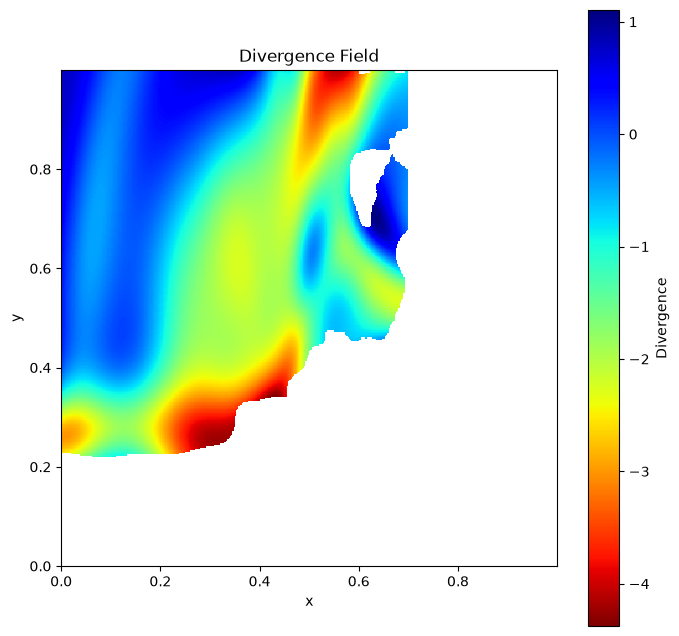

In [26]:
plt.figure(figsize = (8, 8))

plt.pcolormesh(
    # NOTE: 2D inputs
    # NOTE: Take original coords
    torch.tensor(XY_long_tensor[:, 0].reshape(mask.shape)).cpu().detach().numpy(), 
    torch.tensor(XY_long_tensor[:, 1].reshape(mask.shape)).cpu().detach().numpy(),
    divergences_2D_valid.cpu().detach().numpy(), 
    cmap = "jet_r", 
)
plt.colorbar(label = "Divergence")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Divergence Field")
plt.gca().set_aspect("equal")
plt.show()

## 4. Conversion back to physical units

- **dxy = 200_000** because the normalised range [0, 1] presents [0, 200_000 m] (200 km range) in real life.
- **flux_scale = 100_000** because we devided fluxes by 100_000 to achieve ~ 1 std i.e. var of flux in both directions.
- To rescale the div_field to physical units we do **div_phys = div_field * flux_scale / dxy** so div_field * (100_000 / 200_000)
- This simplifies to **dividing by 2** to get **m / year** units.

In [27]:
DIVISOR = 2

# Convert coordinates back to Polar Stereographic coordinates for plotting
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

print("Region span:", x_max - x_min, "x", y_max - y_min)

X_ps = torch.tensor(XY_long_tensor[:, 0].reshape(mask.shape)).cpu().detach().numpy() * (x_max - x_min) + x_min
# Note: undo what we have done in the preprocessing step to get back to polar stereographic coordinates
# ATTENTION: shif y by y_min but scale back by x_span
Y_ps = torch.tensor(XY_long_tensor[:, 1].reshape(mask.shape)).cpu().detach().numpy() * (x_max - x_min) + y_min

Region span: 200000 x 180000


/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_18624/2995785944.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_ps = torch.tensor(XY_long_tensor[:, 0].reshape(mask.shape)).cpu().detach().numpy() * (x_max - x_min) + x_min
/var/folders/pv/_mchxpdj3tz_s_9735cr69pr0000gp/T/ipykernel_18624/2995785944.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Y_ps = torch.tensor(XY_long_tensor[:, 1].reshape(mask.shape)).cpu().detach().numpy() * (x_max - x_min) + y_min


# 5. Visualise model_0 outputs

Note: for now this is div, not bmb so we have to adjust

In [28]:
modis_ross = torch.load("/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt", weights_only = False)

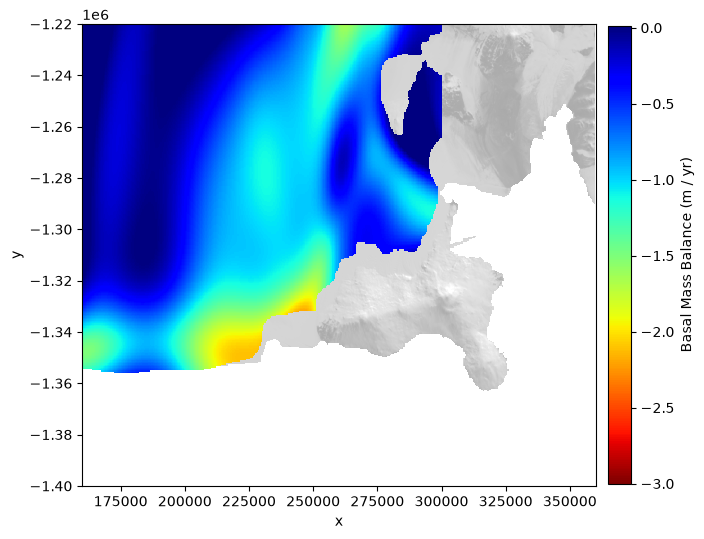

In [29]:
fig, ax = plt.subplots(figsize = (8, 6))

# 1) MODIS as background (draw first)
ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    # NOTE: select channel 3
    modis_ross[3],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.7,
    zorder = 0,
)

# 2) SMB on top (draw second)
pcm = ax.pcolormesh(
    # NOTE: 2D inputs
    # NOTE: Take original coords
    X_ps,
    Y_ps,
    divergences_2D_valid.cpu().detach().numpy() / DIVISOR, 
    vmin = -3,
    vmax = 0.01,
    cmap = "jet_r",
    shading = "auto",
    alpha = 1.0,
    zorder = 1,
)

ax.set_aspect("equal")
# ax.set_axis_off()

# crop
ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

cbar = fig.colorbar(pcm, ax = ax, shrink = 0.99, pad = 0.02)
cbar.set_label("Basal Mass Balance (m / yr)")
plt.xlabel("x")
plt.ylabel("y")

fig.savefig("figures/fluxnet_div_ross.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

## 6. Show ensemble

In [52]:
divergences_2D_valid_from_ensemble = torch.empty((N_ensemble, divergences_2D_valid.shape[0], divergences_2D_valid.shape[1]), dtype = torch.float32)

# Now start from 0 to capture all ensemble members
for e in range(0, N_ensemble):
    print(f"Running inference for ensemble {e}...")

    model = FluxNet().to(device)
    model.load_state_dict(torch.load(f"trained_models/fluxnet_run_{e}_trained_model.pth"))
    # Set model to evaluation mode (no compgraph)
    model.eval()

    divergences_flat = run_inference_in_batches(model, XY_long_tensor, batch_size = 10_000)
    # 1D -> 2D using shapes from the mask
    divergences_2D = divergences_flat.unsqueeze(1).reshape(mask.shape[0], mask.shape[1])

    # Mask out invalid values (where mask != 1) and replace with NaN
    divergences_2D_valid = divergences_2D.masked_fill(mask != 1, float("nan"))

    # Store the valid divergences in the ensemble array
    divergences_2D_valid_from_ensemble[e - 1] = divergences_2D_valid

print(divergences_2D_valid_from_ensemble.shape)

Running inference for ensemble 0...
Processing batch 0 to 10000...
Processing batch 10000 to 20000...
Processing batch 20000 to 30000...
Processing batch 30000 to 40000...
Processing batch 40000 to 50000...
Processing batch 50000 to 60000...
Processing batch 60000 to 70000...
Processing batch 70000 to 80000...
Processing batch 80000 to 90000...
Processing batch 90000 to 100000...
Processing batch 100000 to 110000...
Processing batch 110000 to 120000...
Processing batch 120000 to 130000...
Processing batch 130000 to 140000...
Processing batch 140000 to 144000...
Running inference for ensemble 1...
Processing batch 0 to 10000...
Processing batch 10000 to 20000...
Processing batch 20000 to 30000...
Processing batch 30000 to 40000...
Processing batch 40000 to 50000...
Processing batch 50000 to 60000...
Processing batch 60000 to 70000...
Processing batch 70000 to 80000...
Processing batch 80000 to 90000...
Processing batch 90000 to 100000...
Processing batch 100000 to 110000...
Processing b

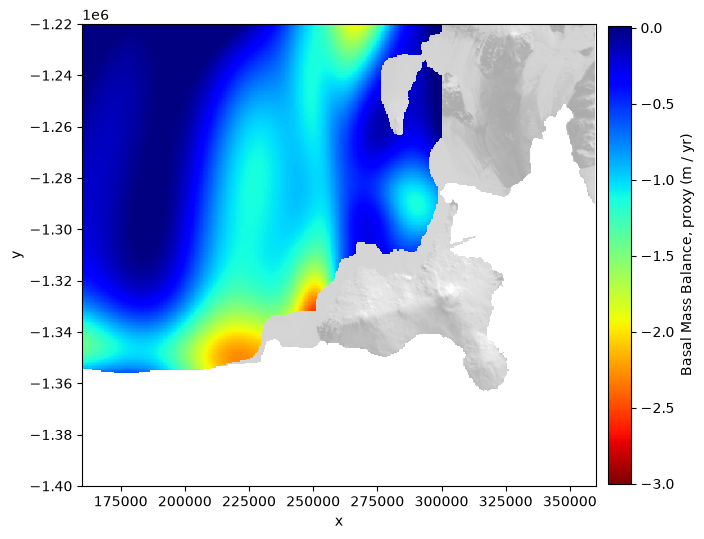

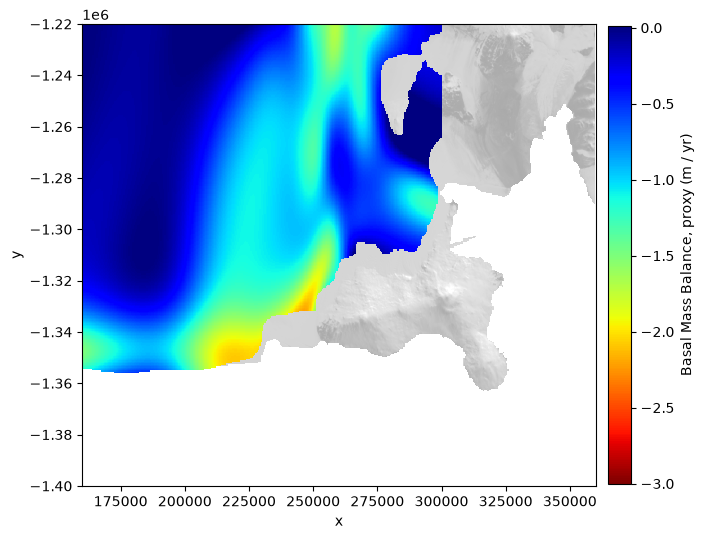

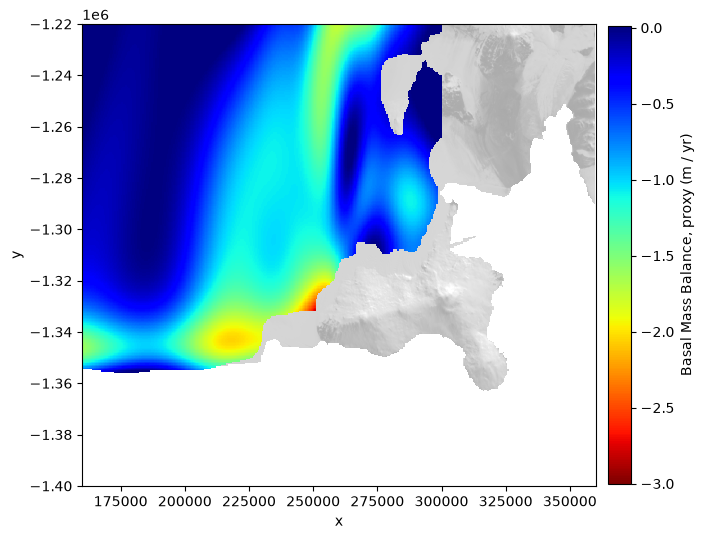

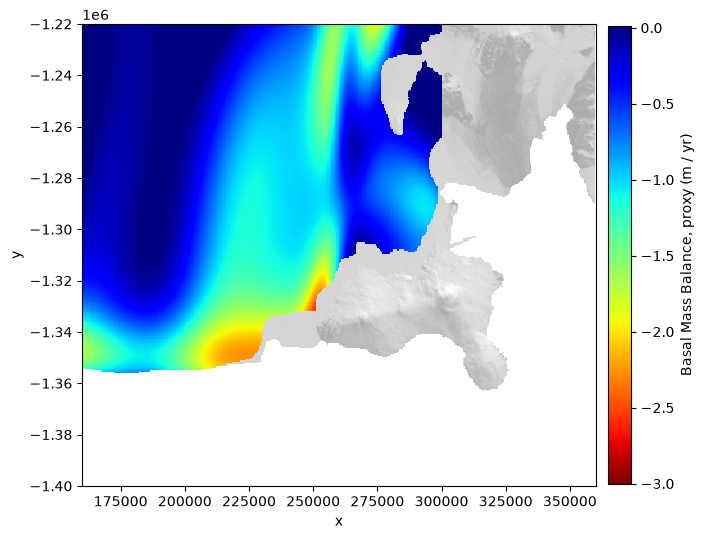

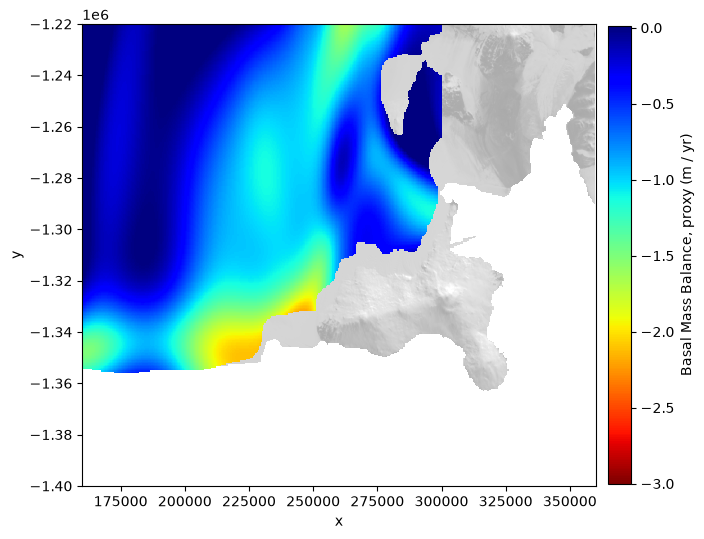

In [56]:
for e in range(0, N_ensemble):
    fig, ax = plt.subplots(figsize = (8, 6))

    # 1) MODIS as background (draw first)
    ax.pcolormesh(
        modis_ross[0],
        modis_ross[1], 
        # NOTE: select channel 3
        modis_ross[3],
        cmap = "gray",
        # softer greys
        vmin = -30_000, 
        vmax = 30_000,
        # as less saturated background
        alpha = 0.7,
        zorder = 0,
    )

    # 2) SMB on top (draw second)
    pcm = ax.pcolormesh(
        # NOTE: 2D inputs
        # NOTE: Take original coords
        X_ps,
        Y_ps,
        divergences_2D_valid_from_ensemble[e].cpu().detach().numpy() / DIVISOR, 
        vmin = -3,
        vmax = 0.01,
        cmap = "jet_r",
        shading = "auto",
        alpha = 1.0,
        zorder = 1,
    )

    ax.set_aspect("equal")
    # ax.set_axis_off()

    # crop
    ax.set_ylim(y_min, y_max)
    ax.set_xlim(x_min, x_max)

    cbar = fig.colorbar(pcm, ax = ax, shrink = 0.99, pad = 0.02)
    cbar.set_label("Basal Mass Balance, proxy (m / yr)")
    plt.xlabel("x")
    plt.ylabel("y")

    fig.savefig(f"figures/ensemble_member_{e}.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)

## Plot variance

In [54]:
ensemble_variance_physical_units = divergences_2D_valid_from_ensemble.std(dim = 0).cpu().detach().numpy() / DIVISOR
print("Ensemble variance shape:", ensemble_variance_physical_units.shape)

Ensemble variance shape: (360, 400)


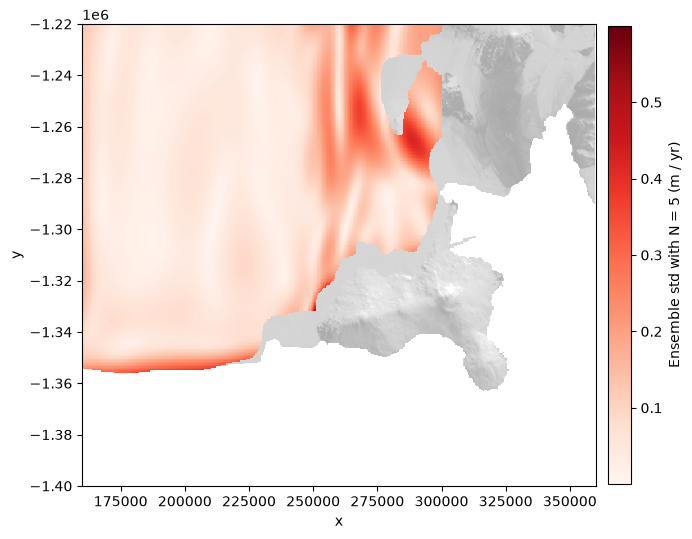

In [55]:
fig, ax = plt.subplots(figsize = (8, 6))

# 1) MODIS as background (draw first)
ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    # NOTE: select channel 3
    modis_ross[3],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.7,
    zorder = 0,
)

# 2) SMB on top (draw second)
pcm = ax.pcolormesh(
    # NOTE: 2D inputs
    # NOTE: Take original coords
    X_ps,
    Y_ps,
    ensemble_variance_physical_units, 
    cmap = "Reds",
    shading = "auto",
    alpha = 1.0,
    zorder = 1,
)

ax.set_aspect("equal")
# ax.set_axis_off()

# crop
ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

cbar = fig.colorbar(pcm, ax = ax, shrink = 0.99, pad = 0.02)
cbar.set_label("Ensemble std with N = 5 (m / yr)")
plt.xlabel("x")
plt.ylabel("y")

fig.savefig("figures/ensemble_std.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)